In [13]:
# generate tasks if we assume the degradation rate is constant

import pandas as pd
import random

# define caissons nb of caissons
N = 10
T = 60
caissons = [i for i in range(N)]  # Index starts from 0

# define degradation rate 
random.seed(40)
# alpha_values = {caisson: round(random.uniform(0.01, 0.05), 6) for caisson in caissons}
alpha_values = {caisson: round(random.uniform(0.001, 0.05), 6) for caisson in caissons}

random.seed(40) # Set seed for reproducibility
# generate random initial pressure values
initial_p_values = {caisson: round(random.uniform(3.2, 3.5), 2) for caisson in caissons}

def generate_tasks(initial_p_values, T, alpha_values):
    # create a dataframe to store the maintenance plan
    columns = ['INDEX', 'CSEM', 'INITIALP', 'ALPHA', 'OPERATION', 'DATE']
    data = []

    # generate maintenance plan
    index = 0  
    for caisson, initial_p in initial_p_values.items():
        current_p = initial_p
        total_days = 0
        alpha = alpha_values[caisson]
        
        while total_days < T:
            # calculate the time to reach 3.2 and take the integer part
            time_to_3_2 = int((current_p - 3.2) / alpha)

            # check if the total days exceed horizon T
            if total_days + time_to_3_2 >= T:
                break

            # add the maintenance plan x task
            operation = 'x'  # only x tasks
            data.append([index, caisson, initial_p, alpha, operation, total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1  # x task takes 1 day
            current_p = 3.5  # reset the pressure to 3.5

    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan

planning = generate_tasks(initial_p_values, T, alpha_values)
print(planning)
planning.to_csv("maintenance_plan_new.csv", index=False)
print("CSV file has been saved successfully")


    INDEX  CSEM  INITIALP     ALPHA OPERATION  DATE
0       0     0      3.34  0.023472         x     5
1       1     0      3.34  0.023472         x    18
2       2     0      3.34  0.023472         x    31
3       3     0      3.34  0.023472         x    44
4       4     0      3.34  0.023472         x    57
5       5     1      3.46  0.044016         x     5
6       6     1      3.46  0.044016         x    12
7       7     1      3.46  0.044016         x    19
8       8     1      3.46  0.044016         x    26
9       9     1      3.46  0.044016         x    33
10     10     1      3.46  0.044016         x    40
11     11     1      3.46  0.044016         x    47
12     12     1      3.46  0.044016         x    54
13     13     2      3.21  0.002560         x     3
14     14     3      3.28  0.014839         x     5
15     15     3      3.28  0.014839         x    26
16     16     3      3.28  0.014839         x    47
17     17     4      3.49  0.048128         x     6
18     18   

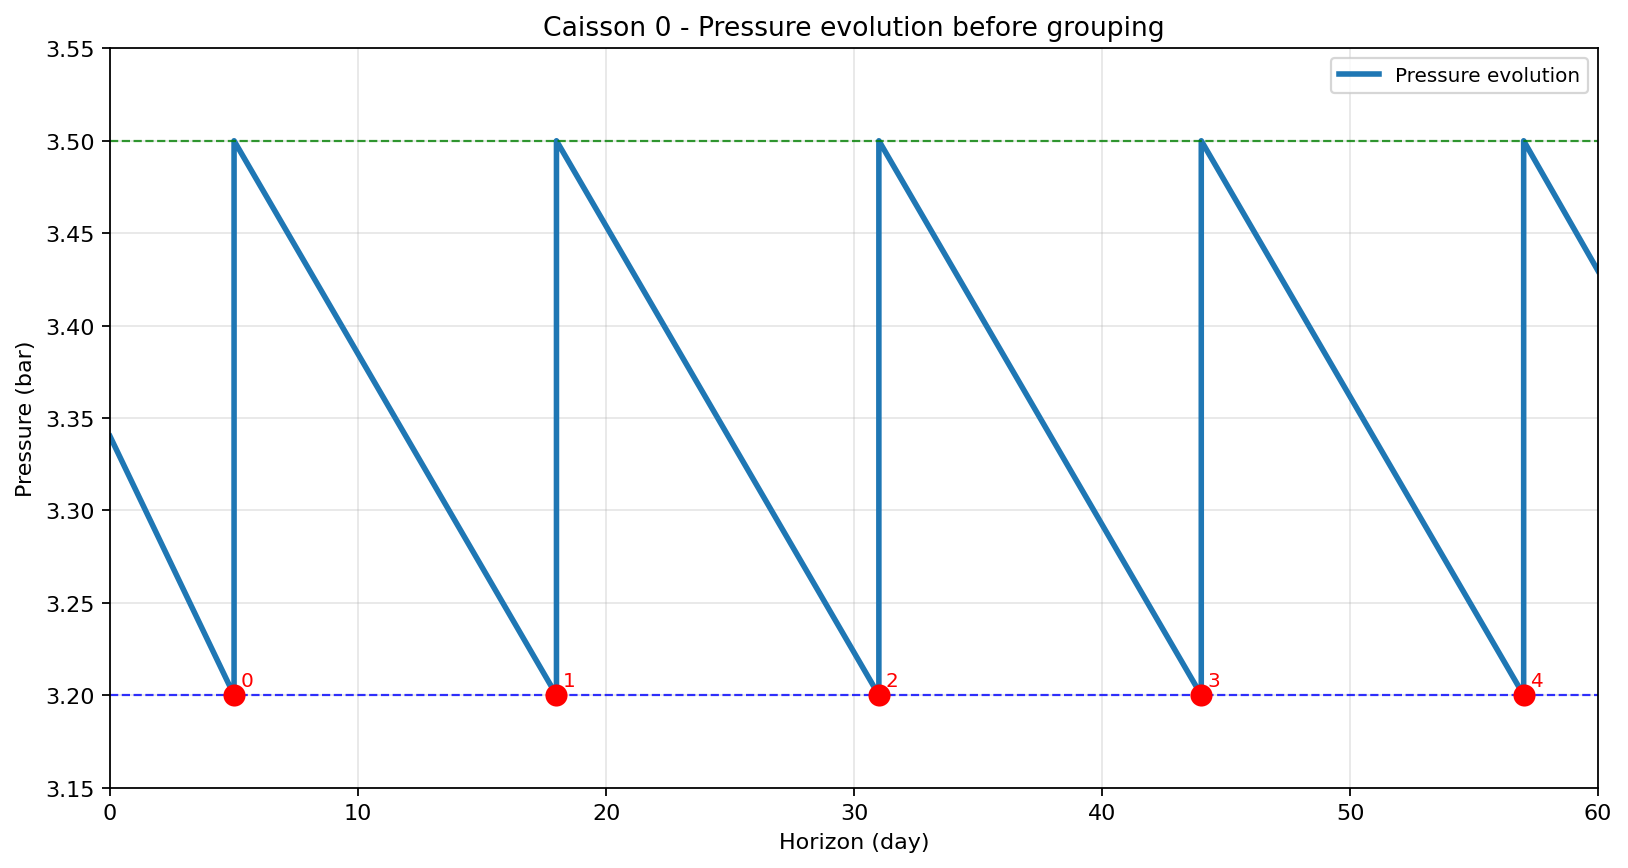

图已保存到：output/caisson_0_vertical_jump_pressure.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# =========================
# 1. 读取任务结果
# =========================
planning = pd.read_csv("maintenance_plan_new.csv")
T = 60

# =========================
# 2. 指定要画哪一个 caisson
# =========================
caisson_idx = 0   # 改成你要的 caisson 编号

tasks = planning[planning["CSEM"] == caisson_idx].copy()
if tasks.empty:
    raise ValueError(f"没有找到 CSEM={caisson_idx} 的任务")

tasks = tasks.sort_values("DATE").reset_index(drop=True)

# 同一个 caisson 全程使用同一个 alpha
alpha = float(tasks.iloc[0]["ALPHA"])
initial_p = float(tasks.iloc[0]["INITIALP"])

# =========================
# 3. 构造“带竖直跳变”的折线
# =========================
x = [0]
y = [initial_p]

current_p = initial_p
current_day = 0

task_days = []
task_labels = []

for _, row in tasks.iterrows():
    task_day = int(row["DATE"])
    task_index = int(row["INDEX"])

    # 先从 current_day 下降到 task_day，保持同一个 alpha
    p_before_task = current_p - alpha * (task_day - current_day)

    # 由于生成任务时就是按达到 3.2 触发，所以这里直接落到 3.2
    x.append(task_day)
    y.append(3.2)

    # 同一天竖直跳回 3.5
    x.append(task_day)
    y.append(3.5)

    # 记录任务点（红点标在 3.2）
    task_days.append(task_day)
    task_labels.append(task_index)

    # 更新状态：从任务当天恢复后继续下降
    current_p = 3.5
    current_day = task_day

# 最后从最后一个任务继续下降到 T
if current_day < T:
    final_p = current_p - alpha * (T - current_day)
    x.append(T)
    y.append(final_p)

# =========================
# 4. 画图
# =========================
fig, ax = plt.subplots(figsize=(12, 6), dpi=160)

# 一条连续折线；同一个 x 上有两个 y，会画出竖直跳变
ax.plot(x, y, color="#1f77b4", linewidth=2.5, label="Pressure evolution")

# 标出所有任务点（3.2）
ax.scatter(task_days, [3.2] * len(task_days), color="red", s=80, zorder=5)

for day, idx in zip(task_days, task_labels):
    ax.annotate(
        f"{idx}\n({day}, {3.2})",
        xy=(day, 3.2),
        xytext=(3, 4),
        textcoords="offset points",
        fontsize=9,
        color="red"
    )

# 参考线
ax.axhline(3.2, color="blue", linestyle="--", linewidth=1, alpha=0.8)
ax.axhline(3.5, color="green", linestyle="--", linewidth=1, alpha=0.8)

ax.set_title(f"Caisson {caisson_idx} - Pressure evolution before grouping")
ax.set_xlabel("Horizon (day)")
ax.set_ylabel("Pressure (bar)")
ax.set_xlim(0, T)
ax.set_ylim(3.15, 3.55)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)

os.makedirs("output", exist_ok=True)
save_path = f"output/caisson_{caisson_idx}_vertical_jump_pressure.png"
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"图已保存到：{save_path}")